# MalVizNet: 32×32

**Project:** Comparative analysis of 12 CNN architectures (M1–M12) for 25-class malware family classification on the Malimg dataset, using grayscale images of malware binaries.

**Data:** The pre-packaged Malimg `.npz` (9,339 images, 25 families), which is only available at 32×32 and is used as is, with no resizing or interpolation. About 21% of the images are exact duplicates (7,378 unique), so some families are almost entirely repeated images; this is checked in the final cells.

**Protocol:**
- **Split:** stratified 70/15/15 into train/validation/test (6,537/1,401/1,401, `random_state=42`).
- **Selection:** checkpoints are chosen on validation accuracy; the test set is used only for final evaluation.
- **Augmentation:** training only, random shift (reflect-pad 3 px, random 32×32 crop). No intensity changes, flips or rotations.
- **Class imbalance:** no class weights or resampling. Imbalance is reported through macro-F1 and per-class recall/precision.
- **Training:** EarlyStopping (patience 15, `val_accuracy`) with best-checkpoint saving.
- **Batch size:** 32 for M1–M8 and 64 for M9–M12; a sensitivity check on M4 and M7 is included.
- **Optimizers:** SGD (momentum 0.9, lr 0.01) for M1–M8, Adam for M9–M12 (lr 1e-3 for M9–M11, 1e-4 for M12). M1 and M2 use lr 0.01 instead of their original, much smaller values, which did not train in this setup.

**Evaluation:** all 12 models on the test set (accuracy, weighted/macro F1, latency, parameters); confusion matrices; seed runs (3 seeds) for the three best models by validation accuracy; per-class precision/recall; accuracy on test images with no exact copy in the training set.

**Known limitations:** 32×32 resolution only; duplicate images across splits; some models stopped at their epoch limit (M1, M2, M6, M10, M11, M12); BatchNorm models (M9–M12) show unstable validation during training; small families have few test images, so their per-class scores are noisy.

**Outputs:** `results_32x32.csv`, `precision_recall_32x32.csv`, `confusion_matrices_32x32.png`, `accuracy_comparison_32x32.png`, `batch_size_check_32x32.csv`, `seed_runs_32x32.csv`, `seed_summary_32x32.csv`, `per_class_32x32.csv/png`, `duplicate_check_32x32.csv`

**Platform:** Kaggle Notebooks (GPU) · TensorFlow / Keras

*Architectures adopted from prior work: Pinhero et al. (2021), Computers & Security, 105, 102247.*

In [1]:
# --- Standard library ---
import os, glob, shutil, time, json

# --- Numeric / data ---
import numpy as np
import pandas as pd
import cv2

# --- TensorFlow / Keras ---
import tensorflow as tf
from tensorflow.keras import layers, models

# --- scikit-learn ---
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support

# --- Plotting ---
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

In [2]:
# --- Configuration: resolution, seed, batch sizes and epoch limits for this phase ---
SEED = 42
RESOLUTION = 32
BATCH_SIZE_DEFAULT = 32   # M1-M8
BATCH_SIZE_BN = 64        # M9–M12
EPOCHS = {'M1':50,'M2':50,'M3':200,'M4':120,'M5':50,'M6':50,'M7':250,'M8':200,
          'M9':30,'M10':30,'M11':30,'M12':30}

CKPT_DIR, HIST_DIR = '/kaggle/working/checkpoints', '/kaggle/working/history'
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(HIST_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TF together

In [3]:
# --- Download Malimg (pre-packaged .npz, 32x32 grayscale) ---
!wget -q https://raw.githubusercontent.com/Hydrogenion/Malimg/master/malimg.npz -O malimg.npz
!ls -lh malimg.npz

# --- Load: single key 'arr' holding an (N, 2) object array of [image, label] rows
data = np.load('malimg.npz', allow_pickle=True)
arr = data['arr']
print(type(arr), arr.shape, arr.dtype)

# --- Split the object array into images and labels ---
images_raw = arr[:, 0]
labels_raw = arr[:, 1]
print(type(images_raw[0]), images_raw[0].shape if hasattr(images_raw[0], 'shape') else images_raw[0])
print(labels_raw[0], type(labels_raw[0]))
print(np.unique(labels_raw).shape)  # should be 25

# --- Convert to dense typed arrays ---
images = np.stack(images_raw).astype(np.uint8)      # (9339, 32, 32)
labels = labels_raw.astype(np.int64)                # integer family IDs 0-24
print(images.shape, images.dtype)
print(labels.shape, labels.dtype)

# --- Sanity check: native size and all 25 classes present ---
assert images.shape[1:] == (32, 32) and len(np.unique(labels)) == 25

-rw-r--r-- 1 root root 14M Oct 30 06:09 malimg.npz
<class 'numpy.ndarray'> (9339, 2) object
<class 'numpy.ndarray'> (32, 32)
0 <class 'int'>
(25,)
(9339, 32, 32) uint8
(9339,) int64


In [4]:
import hashlib
DEDUP = False              # leave False: dedup wipes out classes 5 and 24
USE_CLASS_WEIGHTS = False  # True = mild (sqrt) weights

images_use, labels_use = images, labels
if DEDUP:
    seen, keep = set(), []
    for i, im in enumerate(images):
        h = hashlib.md5(im.tobytes()).hexdigest()
        if h not in seen: seen.add(h); keep.append(i)
    images_use, labels_use = images[keep], labels[keep]

# Normalize to [0, 1]
images_norm = images_use.astype(np.float32) / 255.0

# Stratified 70 / 15 / 15 split: train / validation / test
X_train, X_tmp, y_train, y_tmp = train_test_split(
    images_norm, labels_use, test_size=0.30, stratify=labels_use, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

# Channel axis
X_train_ch, X_val_ch, X_test_ch = [a[..., np.newaxis] for a in (X_train, X_val, X_test)]

# Class weights (off by default; if on, square-rooted so they are much milder)
if USE_CLASS_WEIGHTS:
    cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    class_weight_dict = dict(enumerate(np.sqrt(cw)))
else:
    class_weight_dict = None

(6537, 32, 32) (1401, 32, 32) (1401, 32, 32)


In [5]:
SHIFT_PAD = 3  # pixels

# Shift only: reflect-pad then random crop. No interpolation, no intensity changes.
def augment(image, label):
    p = tf.pad(image, [[SHIFT_PAD, SHIFT_PAD], [SHIFT_PAD, SHIFT_PAD], [0, 0]], mode='REFLECT')
    return tf.image.random_crop(p, size=[RESOLUTION, RESOLUTION, 1]), label

In [6]:
# Clear old checkpoints so stale models are not reused
shutil.rmtree(CKPT_DIR, ignore_errors=True); shutil.rmtree(HIST_DIR, ignore_errors=True)
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(HIST_DIR, exist_ok=True)

def make_datasets(batch_size, seed=SEED):
    tr = (tf.data.Dataset.from_tensor_slices((X_train_ch, y_train))
          .shuffle(len(X_train_ch), seed=seed)
          .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(batch_size).prefetch(tf.data.AUTOTUNE))
    va = (tf.data.Dataset.from_tensor_slices((X_val_ch, y_val))
          .batch(batch_size).prefetch(tf.data.AUTOTUNE))
    return tr, va

def train_model(model, train_ds, val_ds, epochs, class_weight_dict, model_name, skip_if_done=True):
    ckpt, hpath = f'{CKPT_DIR}/{model_name}_best.keras', f'{HIST_DIR}/{model_name}_history.json'
    if skip_if_done and os.path.exists(ckpt) and os.path.exists(hpath):
        print(f'{model_name}: checkpoint found, skipping training.'); return None, None
    cbs = [tf.keras.callbacks.ModelCheckpoint(ckpt, monitor='val_accuracy', save_best_only=True, mode='max'),
           tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=15,
                                            restore_best_weights=True, mode='max')]
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  class_weight=class_weight_dict, callbacks=cbs, verbose=1)
    secs = time.time() - t0
    with open(hpath, 'w') as f:
        json.dump({'history': h.history, 'train_time_sec': secs,
                   'epochs_run': len(h.history['loss'])}, f)
    return h, secs

train_ds, val_ds = make_datasets(BATCH_SIZE_DEFAULT)     # M1-M8
train_ds64, val_ds64 = make_datasets(BATCH_SIZE_BN)      # M9-M12

for imgs, lbls in train_ds.take(1):
    print(imgs.shape, imgs.numpy().min(), imgs.numpy().max())

I0000 00:00:1793340587.306402      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793340587.310007      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


(32, 32, 32, 1) 0.0 1.0


In [7]:
# --- Shared settings for all models ---
NUM_CLASSES = 25
INPUT_SHAPE = (RESOLUTION, RESOLUTION, 1)

def compile_model(model, lr):
    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model
    
def compile_model_adam(model, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [8]:
# M1: Conv + Conv + Pool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 50 epochs
def build_M1(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M1')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m1 = build_M1()
history_m1, time_m1 = train_model(m1, train_ds, val_ds, EPOCHS['M1'], class_weight_dict, 'M1')

Epoch 1/50
 49/205 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2575 - loss: 2.7554

I0000 00:00:1793340594.213853      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


205/205 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.3945 - loss: 2.0971 - val_accuracy: 0.6117 - val_loss: 1.0836
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6356 - loss: 1.0346 - val_accuracy: 0.6795 - val_loss: 0.9447
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7093 - loss: 0.7975 - val_accuracy: 0.7181 - val_loss: 0.7006
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7416 - loss: 0.6880 - val_accuracy: 0.7338 - val_loss: 0.6163
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7447 - loss: 0.6476 - val_accuracy: 0.7930 - val_loss: 0.5755
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7597 - loss: 0.6093 - val_accuracy: 0.7951 - val_loss: 0.5316
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7710 - loss: 0.5898 - val_accuracy: 0.7916 - val_loss: 0.5308
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7759 - loss: 0.5567 - val_accuracy: 0.7816 - val

In [9]:
# M2: Conv + Pool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 50 epochs
def build_M2(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M2')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m2 = build_M2()
history_m2, time_m2 = train_model(m2, train_ds, val_ds, EPOCHS['M2'], class_weight_dict, 'M2')

Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4069 - loss: 2.0010 - val_accuracy: 0.6146 - val_loss: 1.2462
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6286 - loss: 1.0813 - val_accuracy: 0.6674 - val_loss: 1.0392
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6925 - loss: 0.8726 - val_accuracy: 0.7702 - val_loss: 0.6736
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7369 - loss: 0.7314 - val_accuracy: 0.7545 - val_loss: 0.6259
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7386 - loss: 0.6829 - val_accuracy: 0.7744 - val_loss: 0.5920
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7493 - loss: 0.6473 - val_accuracy: 0.7116 - val_loss: 0.7010
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7652 - loss: 0.6046 - val_accuracy: 0.7966 - val_loss: 0.5231
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7624 - loss: 0.5835 - val_accuracy: 0

In [10]:
# M3: Conv + Conv + Conv + Pool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 200 epochs
def build_M3(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M3')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m3 = build_M3()
history_m3, time_m3 = train_model(m3, train_ds, val_ds, EPOCHS['M3'], class_weight_dict, 'M3')

Epoch 1/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4060 - loss: 2.0443 - val_accuracy: 0.6495 - val_loss: 1.0230
Epoch 2/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6505 - loss: 0.9859 - val_accuracy: 0.7081 - val_loss: 0.8059
Epoch 3/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7109 - loss: 0.7916 - val_accuracy: 0.7402 - val_loss: 0.6340
Epoch 4/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7309 - loss: 0.7019 - val_accuracy: 0.7316 - val_loss: 0.6222
Epoch 5/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7468 - loss: 0.6676 - val_accuracy: 0.7802 - val_loss: 0.5830
Epoch 6/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7520 - loss: 0.6222 - val_accuracy: 0.7438 - val_loss: 0.5713
Epoch 7/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7603 - loss: 0.5963 - val_accuracy: 0.8016 - val_loss: 0.5529
Epoch 8/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7586 - loss: 0.5953 - val_acc

In [11]:
# M4: Conv + Pool + Conv + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 120 epochs
def build_M4(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M4')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m4 = build_M4()
history_m4, time_m4 = train_model(m4, train_ds, val_ds, EPOCHS['M4'], class_weight_dict, 'M4')

Epoch 1/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.4211 - loss: 1.9515 - val_accuracy: 0.6602 - val_loss: 0.9755
Epoch 2/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6327 - loss: 1.0422 - val_accuracy: 0.6709 - val_loss: 0.8240
Epoch 3/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6896 - loss: 0.8590 - val_accuracy: 0.7145 - val_loss: 0.7461
Epoch 4/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7237 - loss: 0.7369 - val_accuracy: 0.7545 - val_loss: 0.6556
Epoch 5/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7370 - loss: 0.6802 - val_accuracy: 0.7894 - val_loss: 0.5746
Epoch 6/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7485 - loss: 0.6301 - val_accuracy: 0.7973 - val_loss: 0.5504
Epoch 7/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7666 - loss: 0.5935 - val_accuracy: 0.8101 - val_loss: 0.5064
Epoch 8/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7707 - loss: 0.5703 - val_acc

In [12]:
# M5: Conv + GlobalMaxPool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 50 epochs
def build_M5(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.GlobalMaxPooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M5')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m5 = build_M5()
history_m5, time_m5 = train_model(m5, train_ds, val_ds, EPOCHS['M5'], class_weight_dict, 'M5')

Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.3118 - loss: 2.5606 - val_accuracy: 0.3155 - val_loss: 2.4970
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3228 - loss: 2.4705 - val_accuracy: 0.3155 - val_loss: 2.4102
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3942 - loss: 2.2926 - val_accuracy: 0.4011 - val_loss: 2.1719
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4141 - loss: 2.0599 - val_accuracy: 0.4361 - val_loss: 1.9406
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4371 - loss: 1.8720 - val_accuracy: 0.4697 - val_loss: 1.8226
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4569 - loss: 1.7321 - val_accuracy: 0.4939 - val_loss: 1.6640
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4903 - loss: 1.5980 - val_accuracy: 0.5111 - val_loss: 1.5473
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5166 - loss: 1.4963 - val_accuracy: 0

In [13]:
# M6: Conv + Conv + GlobalMaxPool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 50 epochs
def build_M6(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.GlobalMaxPooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M6')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m6 = build_M6()
history_m6, time_m6 = train_model(m6, train_ds, val_ds, EPOCHS['M6'], class_weight_dict, 'M6')

Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.3041 - loss: 2.5814 - val_accuracy: 0.3155 - val_loss: 2.4885
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3554 - loss: 2.3272 - val_accuracy: 0.4261 - val_loss: 2.0184
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4490 - loss: 1.8164 - val_accuracy: 0.5453 - val_loss: 1.5851
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5250 - loss: 1.4903 - val_accuracy: 0.6431 - val_loss: 1.2808
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5929 - loss: 1.2354 - val_accuracy: 0.6238 - val_loss: 1.0650
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6443 - loss: 1.0582 - val_accuracy: 0.6410 - val_loss: 0.9652
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6638 - loss: 0.9769 - val_accuracy: 0.6424 - val_loss: 0.9026
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6893 - loss: 0.8969 - val_accuracy: 0

In [14]:
# M7: Conv + Pool + Conv + Pool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 250 epochs
def build_M7(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M7')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m7 = build_M7()
history_m7, time_m7 = train_model(m7, train_ds, val_ds, EPOCHS['M7'], class_weight_dict, 'M7')

Epoch 1/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.4107 - loss: 2.0291 - val_accuracy: 0.4847 - val_loss: 1.3006
Epoch 2/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6322 - loss: 1.0771 - val_accuracy: 0.5853 - val_loss: 1.0331
Epoch 3/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6950 - loss: 0.8580 - val_accuracy: 0.6924 - val_loss: 0.8344
Epoch 4/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7178 - loss: 0.7475 - val_accuracy: 0.7780 - val_loss: 0.6193
Epoch 5/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7447 - loss: 0.6616 - val_accuracy: 0.7395 - val_loss: 0.6231
Epoch 6/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7438 - loss: 0.6447 - val_accuracy: 0.7973 - val_loss: 0.5452
Epoch 7/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7462 - loss: 0.6296 - val_accuracy: 0.7416 - val_loss: 0.5907
Epoch 8/250
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7600 - loss: 0.5951 - val_acc

In [15]:
# M8: Conv + Pool + Conv + Pool + Conv + Pool + Dense + Dense | SGD (momentum 0.9), lr = 0.01 | 200 epochs
def build_M8(lr=0.01):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M8')
    return compile_model(m, lr)

tf.keras.utils.set_random_seed(SEED)
m8 = build_M8()
history_m8, time_m8 = train_model(m8, train_ds, val_ds, EPOCHS['M8'], class_weight_dict, 'M8')

Epoch 1/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.3702 - loss: 2.1728 - val_accuracy: 0.4161 - val_loss: 1.5460
Epoch 2/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5786 - loss: 1.2347 - val_accuracy: 0.6188 - val_loss: 1.0625
Epoch 3/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6644 - loss: 0.9363 - val_accuracy: 0.6838 - val_loss: 0.8035
Epoch 4/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7031 - loss: 0.8084 - val_accuracy: 0.6909 - val_loss: 0.9000
Epoch 5/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7168 - loss: 0.7522 - val_accuracy: 0.7787 - val_loss: 0.6098
Epoch 6/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7367 - loss: 0.6703 - val_accuracy: 0.8059 - val_loss: 0.5643
Epoch 7/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7453 - loss: 0.6527 - val_accuracy: 0.7844 - val_loss: 0.6049
Epoch 8/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7574 - loss: 0.6100 - val_acc

In [16]:
# M9: VGG3 baseline (3 stages x 2 Conv+BN+ReLU) + GAP + Dense 512/256/128 | Adam, lr = 0.001 | 30 epochs | batch 64
def build_M9(lr=0.001):
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(64, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(64, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(128, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(256, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'),
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M9')
    return compile_model_adam(m, lr)

tf.keras.utils.set_random_seed(SEED)
m9 = build_M9()
history_m9, time_m9 = train_model(m9, train_ds64, val_ds64, EPOCHS['M9'], class_weight_dict, 'M9')

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - accuracy: 0.6117 - loss: 1.1754 - val_accuracy: 0.0128 - val_loss: 18.3778
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7710 - loss: 0.6423 - val_accuracy: 0.0128 - val_loss: 34.1095
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8351 - loss: 0.5026 - val_accuracy: 0.0264 - val_loss: 23.7876
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8541 - loss: 0.4566 - val_accuracy: 0.0264 - val_loss: 20.7508
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8828 - loss: 0.3645 - val_accuracy: 0.0300 - val_loss: 11.7201
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9006 - loss: 0.3107 - val_accuracy: 0.2684 - val_loss: 3.8102
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9000 - loss: 0.3031 - val_accuracy: 0.5703 - val_loss: 1.3049
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9209 - loss: 0.2485 - va

In [17]:
# M10: VGG3 + BatchNorm + Dropout (conv 0.2/0.3/0.4, dense 0.3/0.3/0.2) | Adam, lr = 0.001 | 30 epochs | batch 64
def build_M10(lr=0.001, dropout_rates=(0.2, 0.3, 0.4)):
    d1, d2, d3 = dropout_rates
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        # Stage 1
        layers.Conv2D(64, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(64, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(d1),
        # Stage 2
        layers.Conv2D(128, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(128, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(d2),
        # Stage 3
        layers.Conv2D(256, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(256, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(d3),
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'), layers.Dropout(0.3),
        layers.Dense(256, activation='relu'), layers.Dropout(0.3),
        layers.Dense(128, activation='relu'), layers.Dropout(0.2),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M10')
    return compile_model_adam(m, lr)

tf.keras.utils.set_random_seed(SEED)
m10 = build_M10()
history_m10, time_m10 = train_model(m10, train_ds64, val_ds64, EPOCHS['M10'], class_weight_dict, 'M10')

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 95ms/step - accuracy: 0.4251 - loss: 1.8091 - val_accuracy: 0.0128 - val_loss: 12.0077
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5854 - loss: 1.1367 - val_accuracy: 0.0128 - val_loss: 27.8090
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6709 - loss: 0.8927 - val_accuracy: 0.0128 - val_loss: 22.5051
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7029 - loss: 0.7821 - val_accuracy: 0.0128 - val_loss: 38.4190
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7246 - loss: 0.7478 - val_accuracy: 0.0264 - val_loss: 14.0639
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7597 - loss: 0.6375 - val_accuracy: 0.1370 - val_loss: 7.8952
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7886 - loss: 0.5889 - val_accuracy: 0.1428 - val_loss: 8.0156
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8036 - loss: 0.5801 - va

In [18]:
# M11: VGG3 + BatchNorm + lighter Dropout (conv 0.1/0.2/0.3, dense 0.2/0.2/0.1) | Adam, lr = 0.001 | 30 epochs | batch 64
def build_M11(lr=0.001):
    d1, d2, d3 = 0.1, 0.2, 0.3
    m = models.Sequential([
        layers.Input(INPUT_SHAPE),
        layers.Conv2D(64, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(64, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(d1),
        layers.Conv2D(128, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(128, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(d2),
        layers.Conv2D(256, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.Conv2D(256, 3, padding='same'), layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(d3),
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'), layers.Dropout(0.2),
        layers.Dense(256, activation='relu'), layers.Dropout(0.2),
        layers.Dense(128, activation='relu'), layers.Dropout(0.1),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='M11')
    return compile_model_adam(m, lr)

tf.keras.utils.set_random_seed(SEED)
m11 = build_M11()
history_m11, time_m11 = train_model(m11, train_ds64, val_ds64, EPOCHS['M11'], class_weight_dict, 'M11')

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.4952 - loss: 1.5669 - val_accuracy: 0.0128 - val_loss: 20.7440
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6810 - loss: 0.8852 - val_accuracy: 0.0128 - val_loss: 35.2123
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7448 - loss: 0.7198 - val_accuracy: 0.0128 - val_loss: 43.5286
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7942 - loss: 0.6071 - val_accuracy: 0.0128 - val_loss: 24.9039
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8175 - loss: 0.5483 - val_accuracy: 0.0443 - val_loss: 17.6139
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8424 - loss: 0.4919 - val_accuracy: 0.5782 - val_loss: 1.8198
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8646 - loss: 0.4329 - val_accuracy: 0.3576 - val_loss: 2.4554
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8816 - loss: 0.3633 - va

In [19]:
# M12: ResNet-50 (random init, grayscale x3) + Dense 1024/512/256 | Adam, lr = 0.0001 | 30 epochs | batch 64
# Note: at 32x32 input the feature map reaches 1x1 by conv5_block1, so about 8M of the ~26M parameters see no spatial context (documented limitation, not a training failure).
def build_M12(lr=0.0001):
    inputs = layers.Input(INPUT_SHAPE)
    # ResNet50 expects 3-channel input; replicate grayscale channel to 3
    x = layers.Concatenate()([inputs, inputs, inputs])

    base_model = tf.keras.applications.ResNet50(
        include_top=False,
        weights=None,
        input_tensor=x,
        pooling='avg'
    )

    x = base_model.output
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    m = models.Model(inputs=inputs, outputs=outputs, name='M12')
    return compile_model_adam(m, lr)

tf.keras.utils.set_random_seed(SEED)
m12 = build_M12()
history_m12, time_m12 = train_model(m12, train_ds64, val_ds64, EPOCHS['M12'], class_weight_dict, 'M12')

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 81s 302ms/step - accuracy: 0.3563 - loss: 2.3186 - val_accuracy: 0.3155 - val_loss: 2.7464
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.4355 - loss: 1.9132 - val_accuracy: 0.3155 - val_loss: 2.9855
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.4644 - loss: 1.7282 - val_accuracy: 0.3155 - val_loss: 3.2476
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.5112 - loss: 1.5412 - val_accuracy: 0.3198 - val_loss: 3.0753
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.5438 - loss: 1.4072 - val_accuracy: 0.3633 - val_loss: 3.0385
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.5654 - loss: 1.2899 - val_accuracy: 0.4418 - val_loss: 1.6985
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.5886 - loss: 1.1939 - val_accuracy: 0.6224 - val_loss: 1.1061
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.6018 - loss: 1.1394 - val_ac

In [20]:
# --- Training summary: epochs run, best epoch, best validation accuracy, training time ---
print(f"{'Model':<6}{'epochs':>7}{'best epoch':>11}{'best val %':>11}{'time (s)':>10}")
for n in [f'M{i}' for i in range(1, 13)]:
    hp = f'{HIST_DIR}/{n}_history.json'
    if not os.path.exists(hp):
        print(f'{n:<6} missing'); continue
    h = json.load(open(hp)); va = h['history']['val_accuracy']
    print(f'{n:<6}{h["epochs_run"]:>7}{va.index(max(va)) + 1:>11}{max(va) * 100:>11.2f}{h["train_time_sec"]:>10.0f}')

Model  epochs best epoch best val %  time (s)
M1         50         49      93.65        47
M2         50         48      92.43        39
M3         53         38      94.08        54
M4         83         68      94.00        69
M5         50         46      72.45        35
M6         50         50      82.44        42
M7         73         58      94.29        61
M8         70         55      94.43        60
M9         30         23      90.36        76
M10        30         25      92.43        79
M11        30         30      92.29        78
M12        30         28      77.37       219


Model  Accuracy  Weighted_F1  Macro_F1  Latency_ms   Params
   M1     93.72        0.933     0.880        0.76  1061497
   M2     92.93        0.926     0.881        0.38  1052249
   M3     94.50        0.941     0.895        0.43  1070745
   M4     94.08        0.938     0.895        0.51  1061497
   M5     70.95        0.690     0.576        0.44     7769
   M6     82.80        0.816     0.787        0.41    17017
   M7     93.79        0.936     0.893        0.52   275065
   M8     94.43        0.942     0.907        0.64    87705
   M9     89.58        0.876     0.784        0.94  1446873
  M10     92.08        0.904     0.806        1.01  1446873
  M11     92.58        0.912     0.829        0.98  1446873
  M12     77.66        0.756     0.700        4.13 26348441


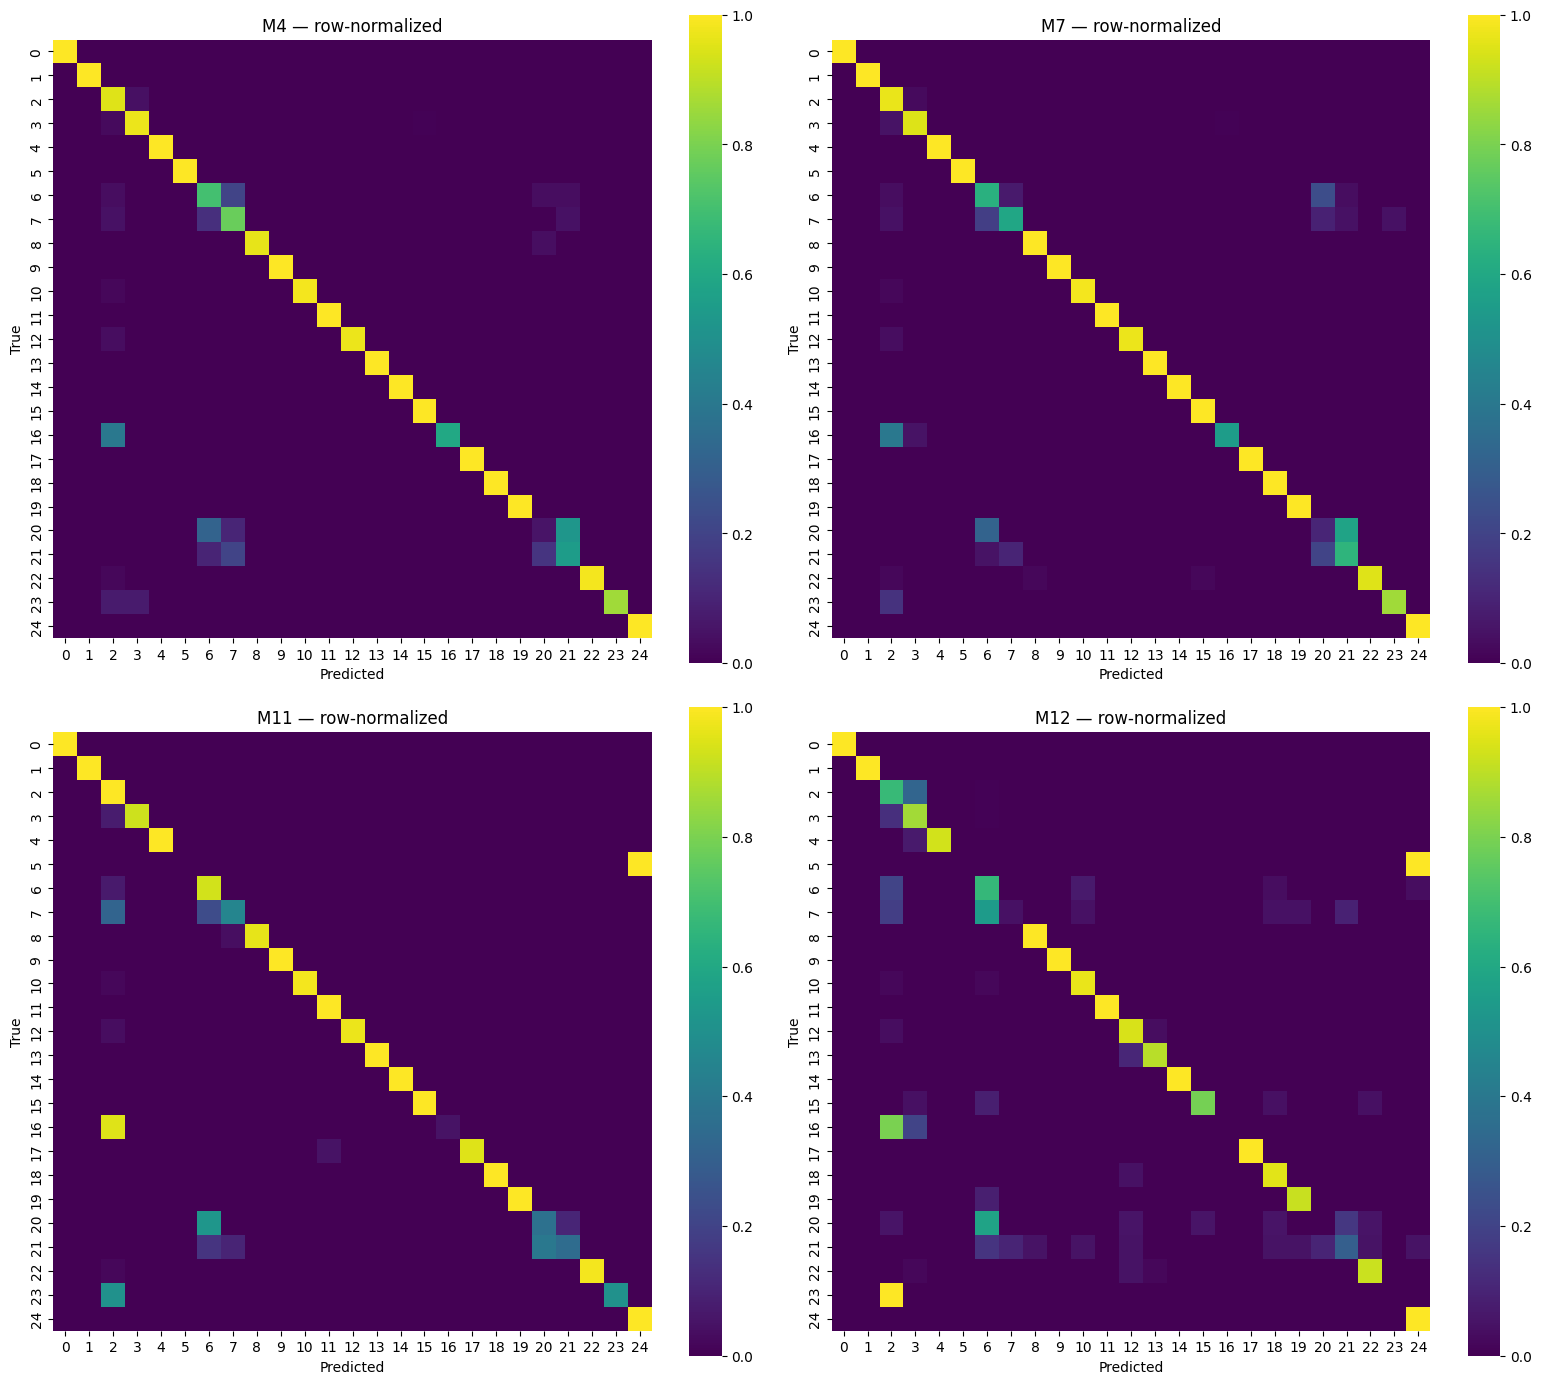

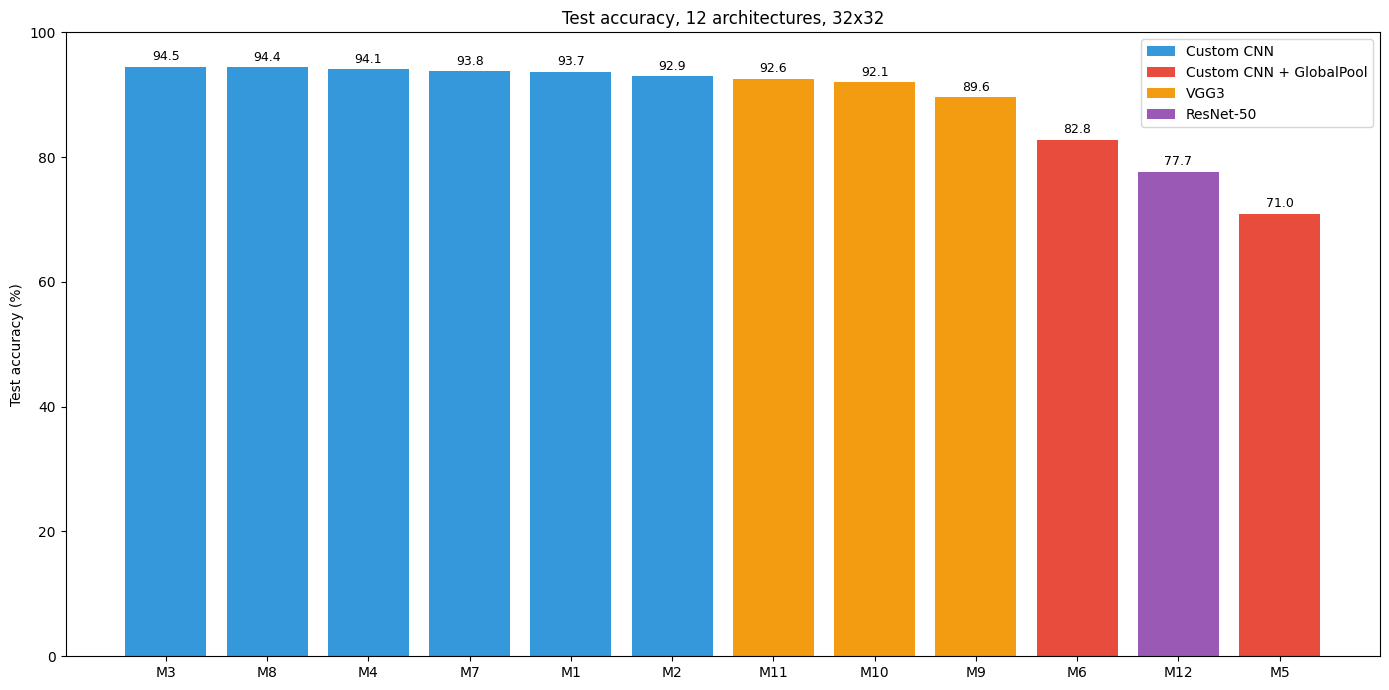

In [21]:
# --- Evaluate all 12 saved models on the test set and export results ---
MODEL_NAMES = [f'M{i}' for i in range(1, 13)]
CM_MODELS = ['M4', 'M7', 'M11', 'M12']      # same four models at every scale
TAG = f'{RESOLUTION}x{RESOLUTION}'
OUT = '/kaggle/working'

# Stop early if any checkpoint is missing (avoids a partial results table)
missing = [n for n in MODEL_NAMES if not os.path.exists(f'{CKPT_DIR}/{n}_best.keras')]
assert not missing, f'Missing checkpoints: {missing}'

rows, pr_rows, preds = [], [], {}
for name in MODEL_NAMES:
    model = tf.keras.models.load_model(f'{CKPT_DIR}/{name}_best.keras')
    model.predict(X_test_ch[:64], verbose=0)                       # warm-up (excluded from timing)
    t0 = time.time()
    probs = model.predict(X_test_ch, batch_size=64, verbose=0)
    latency = (time.time() - t0) / len(X_test_ch) * 1000           # ms per sample
    yp = probs.argmax(axis=1)
    preds[name] = yp

    w_p, w_r, w_f1, _ = precision_recall_fscore_support(y_test, yp, average='weighted', zero_division=0)
    m_p, m_r, m_f1, _ = precision_recall_fscore_support(y_test, yp, average='macro', zero_division=0)

    rows.append(dict(Model=name,
                     Accuracy=round(accuracy_score(y_test, yp) * 100, 2),
                     Weighted_F1=round(w_f1, 3), Macro_F1=round(m_f1, 3),
                     Latency_ms=round(latency, 2), Params=model.count_params()))
    pr_rows.append(dict(Model=name,
                        Weighted_Precision=round(w_p, 3), Weighted_Recall=round(w_r, 3),
                        Macro_Precision=round(m_p, 3), Macro_Recall=round(m_r, 3)))

df = pd.DataFrame(rows)                                             # M1..M12 order
df.to_csv(f'{OUT}/results_{TAG}.csv', index=False)
pd.DataFrame(pr_rows).to_csv(f'{OUT}/precision_recall_{TAG}.csv', index=False)
print(df.to_string(index=False))

# --- Confusion matrices (row-normalized = per-class recall) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, name in zip(axes.ravel(), CM_MODELS):
    sns.heatmap(confusion_matrix(y_test, preds[name], normalize='true'),
                cmap='viridis', vmin=0, vmax=1, square=True, ax=ax)
    ax.set_title(f'{name} — row-normalized'); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout()
plt.savefig(f'{OUT}/confusion_matrices_{TAG}.png', dpi=150, bbox_inches='tight'); plt.show()

# --- Accuracy comparison chart (sorted for display only) ---
fam = {**{m: 'Custom CNN' for m in ['M1', 'M2', 'M3', 'M4', 'M7', 'M8']},
       'M5': 'Custom CNN + GlobalPool', 'M6': 'Custom CNN + GlobalPool',
       'M9': 'VGG3', 'M10': 'VGG3', 'M11': 'VGG3', 'M12': 'ResNet-50'}
col = {'Custom CNN': '#3498db', 'Custom CNN + GlobalPool': '#e74c3c',
       'VGG3': '#f39c12', 'ResNet-50': '#9b59b6'}
d = df.sort_values('Accuracy', ascending=False)
fig, ax = plt.subplots(figsize=(14, 7))
bars = ax.bar(d.Model, d.Accuracy, color=[col[fam[m]] for m in d.Model])
for b, a in zip(bars, d.Accuracy):
    ax.text(b.get_x() + b.get_width() / 2, a + 1, f'{a:.1f}', ha='center', fontsize=9)
ax.set_ylim(0, 100); ax.set_ylabel('Test accuracy (%)')
ax.set_title(f'Test accuracy, 12 architectures, {TAG}')
ax.legend(handles=[Patch(facecolor=c, label=l) for l, c in col.items()])
plt.tight_layout()
plt.savefig(f'{OUT}/accuracy_comparison_{TAG}.png', dpi=150, bbox_inches='tight'); plt.show()

In [22]:
# --- Batch-size sensitivity check: M4 and M7, batch 32 vs 64, 3 seeds each ---
CHECK_SEEDS = [42, 43, 44]
check_rows = []
for name, builder in [('M4', build_M4), ('M7', build_M7)]:
    for bs in (32, 64):
        for s in CHECK_SEEDS:
            run = f'{name}_bs{bs}_s{s}'
            if bs == 32 and s == SEED:
                run = name                    # the main run, already trained above
            else:
                tf.keras.utils.set_random_seed(s)
                tr, te = make_datasets(bs, seed=s)
                train_model(builder(), tr, te, EPOCHS[name], class_weight_dict, run)
            h = json.load(open(f'{HIST_DIR}/{run}_history.json'))
            va = h['history']['val_accuracy']
            check_rows.append(dict(Model=name, Batch=bs, Seed=s, Epochs=h['epochs_run'],
                                    Best_val_acc=round(max(va) * 100, 2)))

check_df = pd.DataFrame(check_rows)
check_df.to_csv(f'{OUT}/batch_size_check_{TAG}.csv', index=False)
print(check_df.to_string(index=False))
print(check_df.groupby(['Model', 'Batch']).Best_val_acc.agg(['mean', 'min', 'max']).round(2))

Epoch 1/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.4322 - loss: 1.9044 - val_accuracy: 0.6367 - val_loss: 1.2954
Epoch 2/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6482 - loss: 0.9985 - val_accuracy: 0.7273 - val_loss: 0.8436
Epoch 3/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7061 - loss: 0.8054 - val_accuracy: 0.7602 - val_loss: 0.6994
Epoch 4/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7311 - loss: 0.7145 - val_accuracy: 0.7930 - val_loss: 0.5951
Epoch 5/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7488 - loss: 0.6575 - val_accuracy: 0.7680 - val_loss: 0.5755
Epoch 6/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7586 - loss: 0.6137 - val_accuracy: 0.7580 - val_loss: 0.6082
Epoch 7/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7629 - loss: 0.5960 - val_accuracy: 0.8187 - val_loss: 0.4984
Epoch 8/120
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7785 - loss: 0.5592 - val_acc

In [23]:
# --- Seed runs: best models by validation accuracy, batch 32, seeds 42/43/44 ---
SEED_RUNS = [('M3', build_M3), ('M8', build_M8), ('M4', build_M4)]
SEEDS = [42, 43, 44]
rows = []
for name, builder in SEED_RUNS:
    for s in SEEDS:
        # seed 42 = main run; M4 seeds 43/44 reuse the batch-size check runs (same setup)
        run = name if s == SEED else f'{name}_bs32_s{s}'
        if s != SEED:
            tf.keras.utils.set_random_seed(s)
            tr, va = make_datasets(BATCH_SIZE_DEFAULT, seed=s)
            train_model(builder(), tr, va, EPOCHS[name], class_weight_dict, run)
        model = tf.keras.models.load_model(f'{CKPT_DIR}/{run}_best.keras')
        yp = model.predict(X_test_ch, batch_size=64, verbose=0).argmax(axis=1)
        rows.append(dict(Model=name, Seed=s,
                         Test_acc=accuracy_score(y_test, yp) * 100,
                         Macro_F1=f1_score(y_test, yp, average='macro', zero_division=0),
                         Weighted_F1=f1_score(y_test, yp, average='weighted', zero_division=0)))

seed_df = pd.DataFrame(rows)
seed_df.to_csv(f'{OUT}/seed_runs_{TAG}.csv', index=False)
print(seed_df.round(3).to_string(index=False))

summary = seed_df.groupby('Model')[['Test_acc', 'Macro_F1', 'Weighted_F1']].agg(['mean', 'std', 'min', 'max']).round(3)
summary.to_csv(f'{OUT}/seed_summary_{TAG}.csv')
print(summary)
for m, g in seed_df.groupby('Model'):
    print(f"{m}: accuracy {g.Test_acc.mean():.2f} ± {g.Test_acc.std():.2f}, macro-F1 {g.Macro_F1.mean():.3f} ± {g.Macro_F1.std():.3f}")

Epoch 1/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4169 - loss: 2.0062 - val_accuracy: 0.5882 - val_loss: 1.4474
Epoch 2/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6226 - loss: 1.0784 - val_accuracy: 0.7259 - val_loss: 0.8343
Epoch 3/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6910 - loss: 0.8374 - val_accuracy: 0.7395 - val_loss: 0.6810
Epoch 4/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7277 - loss: 0.7210 - val_accuracy: 0.7666 - val_loss: 0.6343
Epoch 5/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7407 - loss: 0.6641 - val_accuracy: 0.7809 - val_loss: 0.5637
Epoch 6/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7557 - loss: 0.6245 - val_accuracy: 0.7595 - val_loss: 0.5966
Epoch 7/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7604 - loss: 0.5941 - val_accuracy: 0.7909 - val_loss: 0.5241
Epoch 8/200
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7710 - loss: 0.5587 - val_acc

 Class  Support  M3_P  M3_R  M3_F1  M8_P  M8_R  M8_F1  M4_P  M4_R  M4_F1
     0       18 1.000 1.000  1.000 1.000 1.000  1.000 1.000 1.000  1.000
     1       18 1.000 1.000  1.000 1.000 1.000  1.000 1.000 1.000  1.000
     2      443 0.939 0.980  0.959 0.941 0.964  0.952 0.955 0.953  0.954
     3      239 0.966 0.954  0.960 0.942 0.950  0.946 0.924 0.971  0.947
     4       29 0.967 1.000  0.983 1.000 1.000  1.000 1.000 1.000  1.000
     5       16 1.000 1.000  1.000 1.000 1.000  1.000 1.000 1.000  1.000
     6       30 0.600 0.800  0.686 0.684 0.867  0.765 0.656 0.700  0.677
     7       22 0.833 0.455  0.588 0.778 0.636  0.700 0.567 0.773  0.654
     8       27 1.000 1.000  1.000 1.000 1.000  1.000 1.000 0.963  0.981
     9       24 1.000 1.000  1.000 1.000 1.000  1.000 1.000 1.000  1.000
    10       57 1.000 0.982  0.991 1.000 0.982  0.991 1.000 0.982  0.991
    11       65 1.000 1.000  1.000 1.000 1.000  1.000 1.000 1.000  1.000
    12       32 1.000 0.969  0.984 1.000 0.938  0.9

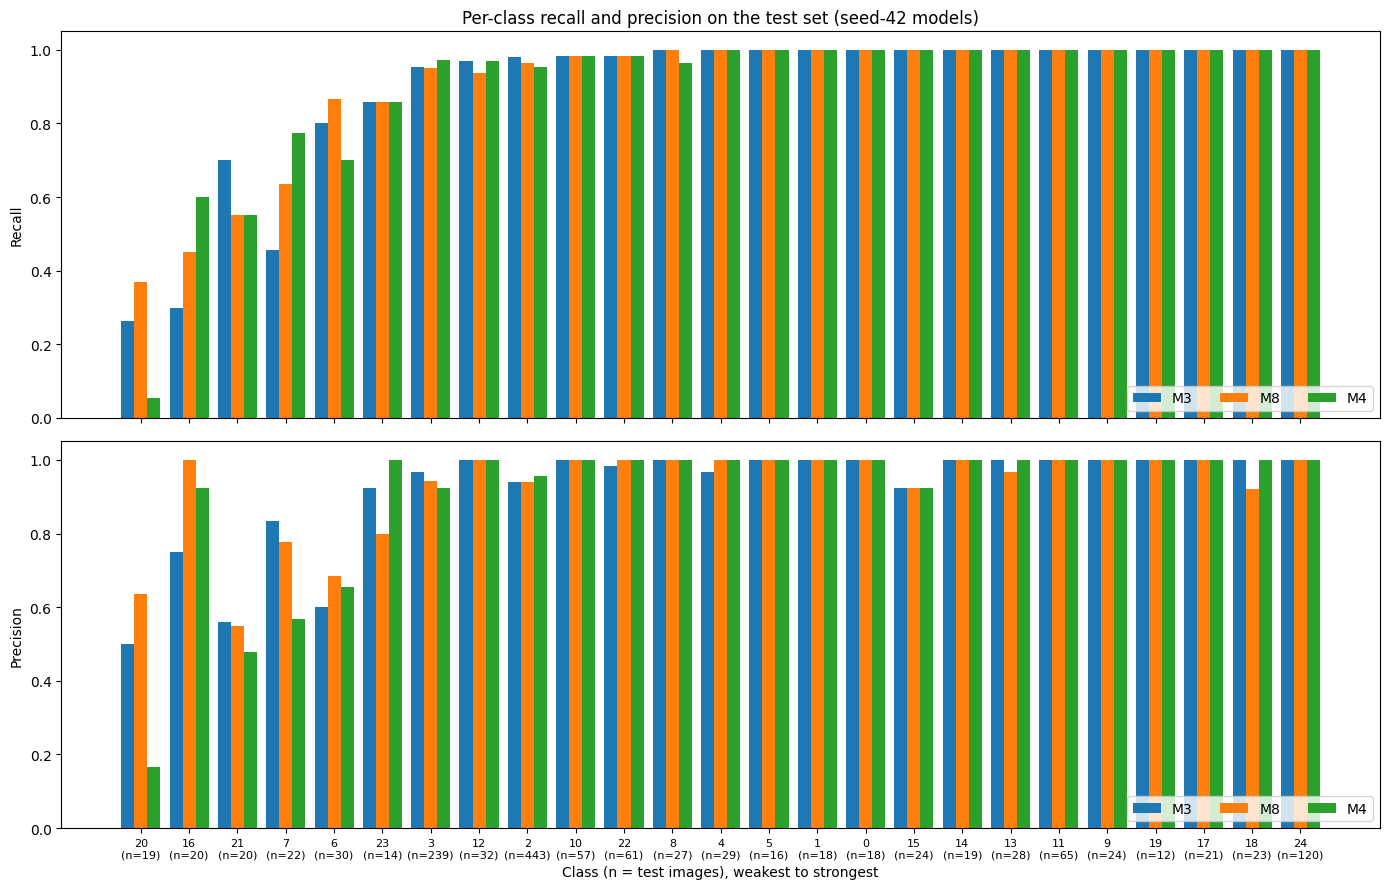

In [24]:
# --- Per-class precision/recall/F1 for M3, M8, M4 (seed-42 checkpoints) ---
names = ['M3', 'M8', 'M4']
pc = pd.DataFrame({'Class': range(25)})
for n in names:
    model = tf.keras.models.load_model(f'{CKPT_DIR}/{n}_best.keras')
    yp = model.predict(X_test_ch, batch_size=64, verbose=0).argmax(axis=1)
    p, r, f, sup = precision_recall_fscore_support(y_test, yp, labels=list(range(25)), zero_division=0)
    pc[f'{n}_P'], pc[f'{n}_R'], pc[f'{n}_F1'] = p.round(3), r.round(3), f.round(3)
pc.insert(1, 'Support', sup)
pc.to_csv(f'{OUT}/per_class_{TAG}.csv', index=False)
print(pc.to_string(index=False))

# --- Combined chart: classes sorted from weakest to strongest mean recall ---
tbl = pc.set_index('Class')
order = tbl[[f'{n}_R' for n in names]].mean(axis=1).sort_values().index.tolist()
x = np.arange(25); w = 0.27
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, (s, t) in zip(axes, [('R', 'Recall'), ('P', 'Precision')]):
    for i, n in enumerate(names):
        ax.bar(x + (i - 1) * w, tbl.loc[order, f'{n}_{s}'].values, w, label=n)
    ax.set_ylim(0, 1.05); ax.set_ylabel(t); ax.legend(loc='lower right', ncol=3)
axes[0].set_title('Per-class recall and precision on the test set (seed-42 models)')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{c}\n(n={tbl.loc[c, "Support"]})' for c in order], fontsize=8)
axes[1].set_xlabel('Class (n = test images), weakest to strongest')
plt.tight_layout()
plt.savefig(f'{OUT}/per_class_{TAG}.png', dpi=150, bbox_inches='tight'); plt.show()

In [25]:
# --- Stricter test: accuracy on test images with no exact copy in the training set ---
train_set = {x.tobytes() for x in X_train}
seen = np.array([x.tobytes() in train_set for x in X_test])
print(f'Test images: {len(seen)} | with exact copy in train: {seen.sum()} ({seen.mean()*100:.1f}%)')

rows = []
for n in ['M3', 'M8', 'M4']:
    model = tf.keras.models.load_model(f'{CKPT_DIR}/{n}_best.keras')
    yp = model.predict(X_test_ch, batch_size=64, verbose=0).argmax(axis=1)
    rows.append(dict(
        Model=n,
        All_test=accuracy_score(y_test, yp) * 100,
        Has_train_copy=accuracy_score(y_test[seen], yp[seen]) * 100,
        No_train_copy=accuracy_score(y_test[~seen], yp[~seen]) * 100,
        Macro_F1_no_copy=f1_score(y_test[~seen], yp[~seen], average='macro', zero_division=0)))
dup_df = pd.DataFrame(rows).round(3)
print(dup_df.to_string(index=False))
dup_df.to_csv(f'{OUT}/duplicate_check_{TAG}.csv', index=False)

Test images: 1401 | with exact copy in train: 313 (22.3%)
Model  All_test  Has_train_copy  No_train_copy  Macro_F1_no_copy
   M3    94.504           100.0         92.923             0.807
   M8    94.433           100.0         92.831             0.822
   M4    94.076           100.0         92.371             0.805
